# 01 · Spatial filters and colour spaces

**Owner:** Member A (classical processing & texture) · **Labs:** 2 (mean filter, Gaussian blur, Laplacian sharpening) and
4 (RGB → grayscale, HSV, LAB) · **Requirements:** REQ-02, REQ-03; spec Sections 8.2–8.3.

### Objective
* Compare denoising and detail enhancement on the **same original grayscale ROI** before edges/thresholds.
* Quantify denoising only where a clean reference exists (synthetic noise experiment: MSE / PSNR).
* Show every colour channel in its correct numeric convention and compare hair vs scalp patch statistics.

### Conventions used (from `configs/default.yaml`)
* One boundary policy for every filter: `BORDER_REFLECT_101`.
* Signed results (Laplacian, sharpened image) stay `float64`; only display copies are clipped to `uint8`.
* Extra comparisons beyond the lab list (median, bilateral) are labelled as such.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

# Robust project-root discovery: works from notebooks/ or the project root, installed or not.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "default.yaml").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scalptrack.config import load_config, seed_everything, project_path, display_path
from scalptrack.demo_data import dataset_status, development_images, synthetic_closeups, figure_path
import cv2
from scalptrack import preprocessing as pp
from scalptrack.edges import sobel_gradients
from scalptrack.segmentation import threshold_otsu, hair_candidate_mask
from scalptrack.viz import show_grid

cfg = load_config()
rng = seed_everything(cfg["seed"])
NB = "01_filters_color"
rel = lambda p: display_path(p, ROOT)  # noqa: E731 - short path for printing
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 90
print("project root:", ROOT)
print("config:", Path(cfg["config_path"]).name, "| seed:", cfg["seed"])

project root: C:\Riddhi_Projects\ScalpTrack
config: default.yaml | seed: 42


In [2]:
def save_fig(fig, name, provenance):
    """Save under outputs/figures/<NB>/<real|synthetic>/ ; synthetic figures get a caption and SYNTHETIC_ prefix."""
    from scalptrack.viz import synthetic_banner
    if provenance == "synthetic":
        synthetic_banner(fig)
    p = figure_path(cfg, NB, name, provenance)
    fig.savefig(p, dpi=120, bbox_inches="tight")
    print("saved", rel(p))
    return p

In [3]:
STATUS = dataset_status(cfg)
print(STATUS["message"])
REAL = STATUS["available"]
DEV = development_images(cfg, n_per_class=1, max_total=4) if REAL else []
SYN = synthetic_closeups(cfg)
print(f"real development images loaded: {len(DEV)} (train/validation only) | synthetic fixtures: {list(SYN)}")

REAL DATASET NOT AVAILABLE - synthetic fixtures are used below.
Dataset 'kaggle_hair_diseases' was not found or contains no images.
Download it from https://www.kaggle.com/datasets/sundarannamalai/hair-diseases (license: CC BY-NC-SA 4.0) and extract it so that:
  C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<optional wrapper folder>\train\<Class Name>\*.jpg
  C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<optional wrapper folder>\val\<Class Name>\*.jpg
  C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<optional wrapper folder>\test\<Class Name>\*.jpg
  (or, without a publisher split: C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<Class Name>\*.jpg)
See docs/dataset_setup.md for step-by-step instructions.


real development images loaded: 0 (train/validation only) | synthetic fixtures: ['clean', 'flakes', 'shadow', 'glare', 'light_hair', 'blurred']


In [4]:
# Inputs: real development images (if downloaded) + the synthetic close-up. Each keeps its provenance.
INPUTS = [(d["rgb"], d["image_id"], "real") for d in DEV[:2]] + [(SYN["clean"]["rgb"], "closeup", "synthetic")]
print("filter parameters:", cfg["filters"])
param_table = pd.DataFrame([
    {"filter": "mean (box)", "lab": 2, "kernel": cfg["filters"]["mean_kernels"], "other": "-"},
    {"filter": "Gaussian", "lab": 2, "kernel": cfg["filters"]["gaussian_kernels"], "other": f"sigma={cfg['filters']['gaussian_sigma']}"},
    {"filter": "Laplacian sharpening", "lab": 2, "kernel": f"ksize={cfg['filters']['laplacian_ksize']} (3x3, centre -4)",
     "other": f"I - {cfg['filters']['laplacian_alpha']} * Laplacian(I)"},
    {"filter": "median (extra)", "lab": "-", "kernel": cfg["filters"]["median_kernels"], "other": "non-linear"},
    {"filter": "bilateral (extra)", "lab": "-", "kernel": cfg["filters"]["bilateral"]["d"],
     "other": f"sigma_color={cfg['filters']['bilateral']['sigma_color']}, sigma_space={cfg['filters']['bilateral']['sigma_space']}"},
])
param_table

filter parameters: {'border': 'reflect101', 'mean_kernels': [3, 5], 'gaussian_kernels': [3, 5], 'gaussian_sigma': 1.0, 'median_kernels': [3, 5], 'bilateral': {'d': 7, 'sigma_color': 50, 'sigma_space': 7}, 'laplacian_alpha': 0.5, 'laplacian_ksize': 1, 'synthetic_noise_sigma': 15.0}


,filter,lab,kernel,other
0,mean (box),2,"[3, 5]",-
1,Gaussian,2,"[3, 5]",sigma=1.0
2,Laplacian sharpening,2,"ksize=1 (3x3, centre -4)",I - 0.5 * Laplacian(I)
3,median (extra),-,"[3, 5]",non-linear
4,bilateral (extra),-,7,"sigma_color=50, sigma_space=7"


## 1. Lab 2 — filter comparison on the same grayscale ROI

saved outputs/figures/01_filters_color/synthetic/SYNTHETIC_filters_contact_sheet_closeup.png


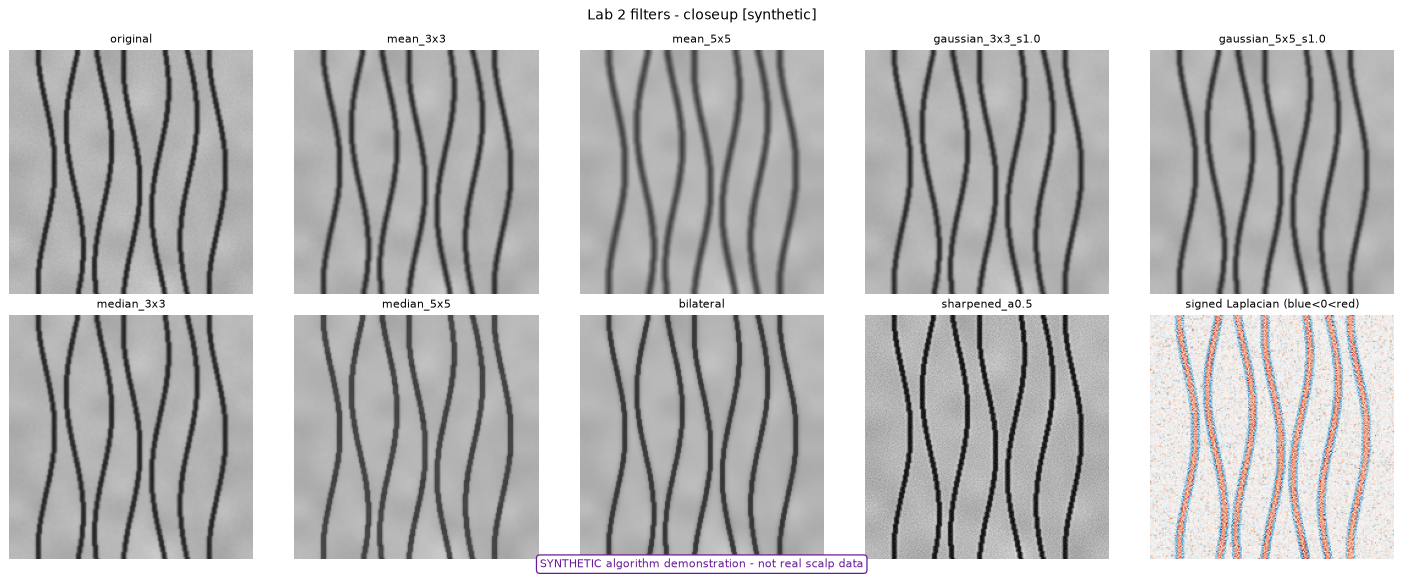

In [5]:
for rgb, name, prov in INPUTS:
    gray = pp.to_gray(rgb)
    out = pp.compare_filters(gray, cfg)
    keys = [k for k in out if k != "laplacian"]
    imgs = [pp.to_display_uint8(out[k]) if out[k].dtype != np.uint8 else out[k] for k in keys] + [out["laplacian"]]
    fig = show_grid(imgs, keys + ["signed Laplacian (blue<0<red)"], ncols=5, signed={len(imgs) - 1},
                    suptitle=f"Lab 2 filters - {name} [{prov}]")
    save_fig(fig, f"filters_contact_sheet_{name}", prov); plt.show()

### 1.1 Zoomed detail and downstream effect
A zoomed crop makes shaft-edge softening visible. Two downstream numbers are compared per filter on the same ROI:
mean Sobel gradient magnitude (detail/edge response) and the Otsu hair-candidate fraction (effect on masks).
These are descriptive — without ground truth they do not say which filter is "correct".

saved outputs/figures/01_filters_color/synthetic/SYNTHETIC_filters_zoom_closeup.png


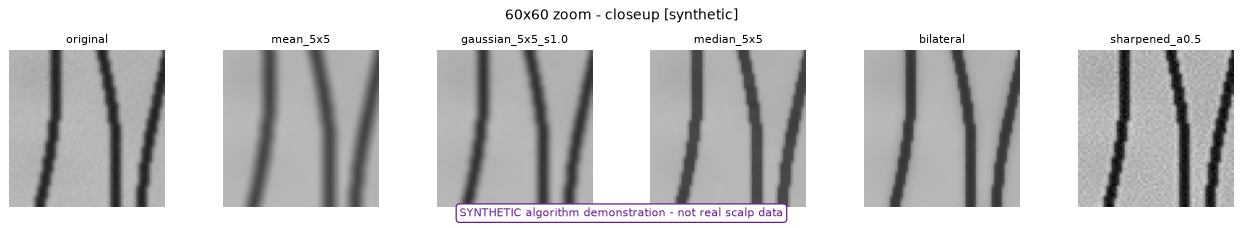

,image,provenance,filter,mean_sobel_magnitude,otsu_threshold,otsu_dark_fraction
0,closeup,synthetic,original,88.381,116.0,0.142
1,closeup,synthetic,mean_3x3,76.964,123.0,0.152
2,closeup,synthetic,mean_5x5,62.625,136.0,0.211
3,closeup,synthetic,gaussian_3x3_s1.0,78.586,122.0,0.151
4,closeup,synthetic,gaussian_5x5_s1.0,74.001,125.0,0.157
5,closeup,synthetic,median_3x3,82.936,117.0,0.142
6,closeup,synthetic,median_5x5,67.007,124.0,0.145
7,closeup,synthetic,bilateral,72.958,119.0,0.142
8,closeup,synthetic,sharpened_a0.5,116.585,94.0,0.142


In [6]:
rows = []
for rgb, name, prov in INPUTS:
    gray = pp.to_gray(rgb)
    out = pp.compare_filters(gray, cfg)
    h, w = gray.shape
    crop = (slice(h // 3, h // 3 + 60), slice(w // 3, w // 3 + 60))
    keys = ["original", "mean_5x5", next(k for k in out if k.startswith("gaussian_5")), "median_5x5", "bilateral",
            next(k for k in out if k.startswith("sharpened"))]
    fig = show_grid([pp.to_display_uint8(out[k])[crop] for k in keys], keys, ncols=6, size=2.4,
                    suptitle=f"60x60 zoom - {name} [{prov}]")
    save_fig(fig, f"filters_zoom_{name}", prov); plt.show()
    for k, arr in out.items():
        if k == "laplacian":
            continue
        disp = pp.to_display_uint8(arr)
        mask, t = threshold_otsu(disp)
        rows.append({"image": name, "provenance": prov, "filter": k,
                     "mean_sobel_magnitude": float(sobel_gradients(disp)["magnitude"].mean()),
                     "otsu_threshold": t, "otsu_dark_fraction": float(mask.mean())})
downstream = pd.DataFrame(rows)
downstream.round(3)

Smoothing lowers the gradient magnitude (detail loss); sharpening raises it (noise and edge amplification). The
Otsu foreground fraction changes only slightly here, but adaptive/fixed thresholds react more strongly
(notebook 02). **Aggressive sharpening is therefore not the default input to width measurement** — it moves the
mask boundary.

## 2. Synthetic noise experiment — MSE / PSNR against a known clean image
Only possible because the clean fixture is known by construction. For real photographs no clean reference exists,
so no PSNR improvement is claimed for them.

noise_sigma,10.0,15.0,25.0
filter,,,
gaussian_3x3_s1.0,31.90,30.50,27.79
bilateral,31.88,30.44,26.85
median_3x3,33.16,30.22,26.58
mean_3x3,30.78,29.77,27.57
gaussian_5x5_s1.0,29.79,29.16,27.60
median_5x5,30.01,28.94,26.62
mean_5x5,24.72,24.61,24.27
noisy input,28.10,24.58,20.18
sharpened_a0.5,17.92,15.07,11.72


saved outputs/figures/01_filters_color/synthetic/SYNTHETIC_noise_experiment.png


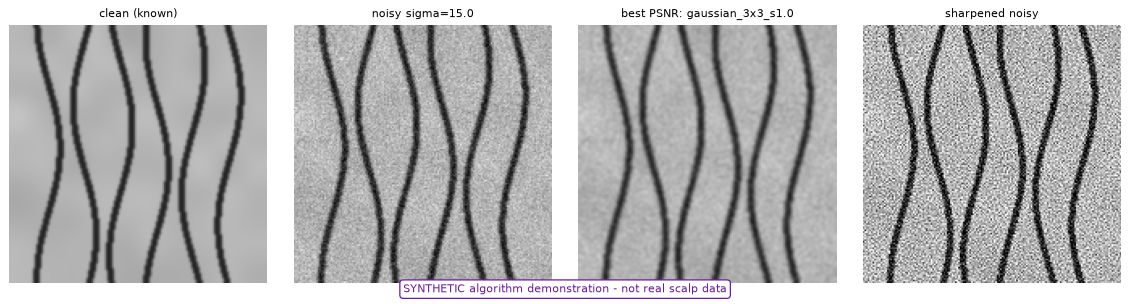

In [7]:
from scalptrack.synthetic import clean_noisy_pair
rows = []
for sigma in (10.0, cfg["filters"]["synthetic_noise_sigma"], 25.0):
    pair = clean_noisy_pair(noise_sigma=sigma, seed=cfg["seed"])
    outs = pp.compare_filters(pair["noisy"], cfg)
    for k, arr in outs.items():
        if k == "laplacian":
            continue
        rows.append({"noise_sigma": sigma, "filter": "noisy input" if k == "original" else k,
                     "MSE": pp.mse(pair["clean"], pp.to_display_uint8(arr)),
                     "PSNR_dB": pp.psnr(pair["clean"], pp.to_display_uint8(arr))})
psnr_table = pd.DataFrame(rows)
piv = psnr_table.pivot(index="filter", columns="noise_sigma", values="PSNR_dB").sort_values(cfg["filters"]["synthetic_noise_sigma"], ascending=False)
piv.to_csv(project_path(cfg, "results", "01_filters_color", "SYNTHETIC_psnr_table.csv", create=True))
display(piv.round(2))
pair = clean_noisy_pair(noise_sigma=cfg["filters"]["synthetic_noise_sigma"], seed=cfg["seed"])
outs = pp.compare_filters(pair["noisy"], cfg)
best = piv.index[0]
fig = show_grid([pair["clean"], pair["noisy"], pp.to_display_uint8(outs[best]),
                 pp.to_display_uint8(outs[next(k for k in outs if k.startswith("sharpened"))])],
                ["clean (known)", f"noisy sigma={pair['noise_sigma']}", f"best PSNR: {best}", "sharpened noisy"], ncols=4)
save_fig(fig, "noise_experiment", "synthetic"); plt.show()

**Interpretation.** Smoothing filters raise PSNR on Gaussian noise; larger kernels help more at higher noise but
blur thin shafts. Laplacian sharpening *lowers* PSNR because it amplifies noise — it enhances detail, it does not
denoise. The ranking is specific to this synthetic noise model.

### 2.1 Laplacian sharpening strength (alpha sweep)
Noise amplification is measured as the standard deviation inside a flat scalp-only patch of the synthetic image
(known to contain no hair).

saved outputs/figures/01_filters_color/synthetic/SYNTHETIC_laplacian_alpha_sweep.png


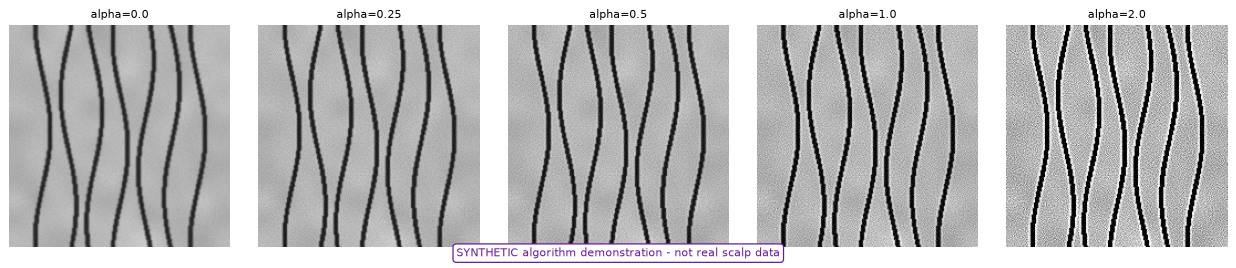

,alpha,flat_patch_std,min,max,fraction_clipped_on_display
0,0.00,5.464,29.00,206.0,0.000
1,0.25,7.354,10.75,215.0,0.000
2,0.50,9.839,-8.50,226.5,0.000
3,1.00,15.420,-47.00,260.0,0.026
4,2.00,27.236,-124.00,334.0,0.128


In [8]:
gray = pp.to_gray(SYN["clean"]["rgb"])
flat = ~cv2.dilate(SYN["clean"]["hair_truth"].astype(np.uint8), np.ones((9, 9), np.uint8)).astype(bool)
rows, imgs, titles = [], [], []
for a in (0.0, 0.25, 0.5, 1.0, 2.0):
    s = pp.laplacian_sharpen(gray, a)
    rows.append({"alpha": a, "flat_patch_std": float(s[flat].std()), "min": float(s.min()), "max": float(s.max()),
                 "fraction_clipped_on_display": float(((s < 0) | (s > 255)).mean())})
    imgs.append(pp.to_display_uint8(s)); titles.append(f"alpha={a}")
fig = show_grid(imgs, titles, ncols=5, size=2.8); save_fig(fig, "laplacian_alpha_sweep", "synthetic"); plt.show()
pd.DataFrame(rows).round(3)

## 3. Lab 4 — colour spaces and numeric conventions

| Space | OpenCV `uint8` encoding | Physical meaning |
|---|---|---|
| Gray | `0.299R + 0.587G + 0.114B` | luminance-like intensity |
| HSV | H ∈ [0, 179] (= degrees / 2), S, V ∈ [0, 255] | hue angle wraps at 360° |
| LAB (8-bit) | L·255/100, a + 128, b + 128 | **not** textbook signed a*/b* |
| LAB (float input 0–1) | L ∈ [0, 100], a*, b* signed | used for features in this project |

The cell below checks the 8-bit ↔ float LAB relationship numerically instead of assuming it.

In [9]:
rgb = SYN["flakes"]["rgb"]
lab8 = pp.to_lab_uint8(rgb); labf = pp.to_lab_float(rgb)
conv = pp.lab_uint8_to_signed(lab8)
check = pd.DataFrame({
    "channel": ["L", "a", "b"],
    "uint8 raw mean": [lab8[..., i].mean() for i in range(3)],
    "uint8 -> signed mean": [conv[..., i].mean() for i in range(3)],
    "float LAB mean": [labf[..., i].mean() for i in range(3)],
    "max |difference|": [np.abs(conv[..., i] - labf[..., i]).max() for i in range(3)],
})
display(check.round(2))
hsv = pp.to_hsv(rgb)
print("raw OpenCV hue range:", hsv[..., 0].min(), "-", hsv[..., 0].max(), "(degrees/2)")

,channel,uint8 raw mean,uint8 -> signed mean,float LAB mean,max |difference|
0,L,166.68,65.370003,65.239998,0.45
1,a,139.93,11.930000,11.900000,1.58
2,b,142.71,14.710000,14.680000,1.34


raw OpenCV hue range: 0 - 179 (degrees/2)


saved outputs/figures/01_filters_color/synthetic/SYNTHETIC_color_channels_closeup.png


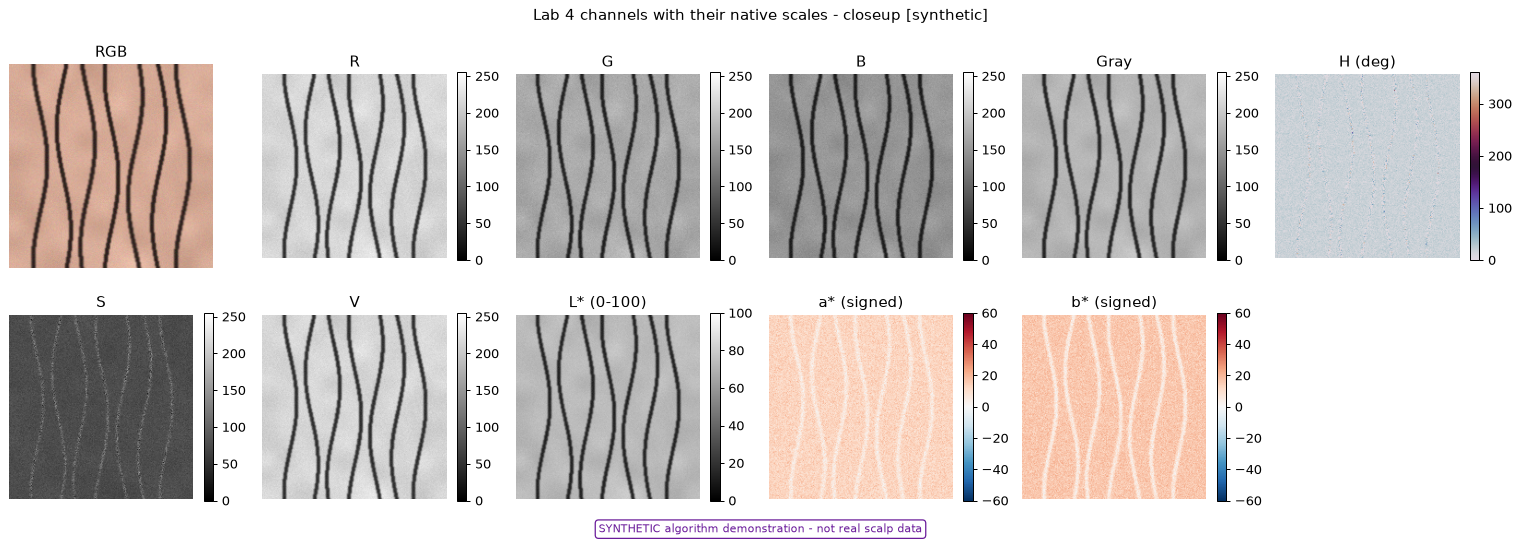

saved outputs/figures/01_filters_color/synthetic/SYNTHETIC_color_channels_flakes.png


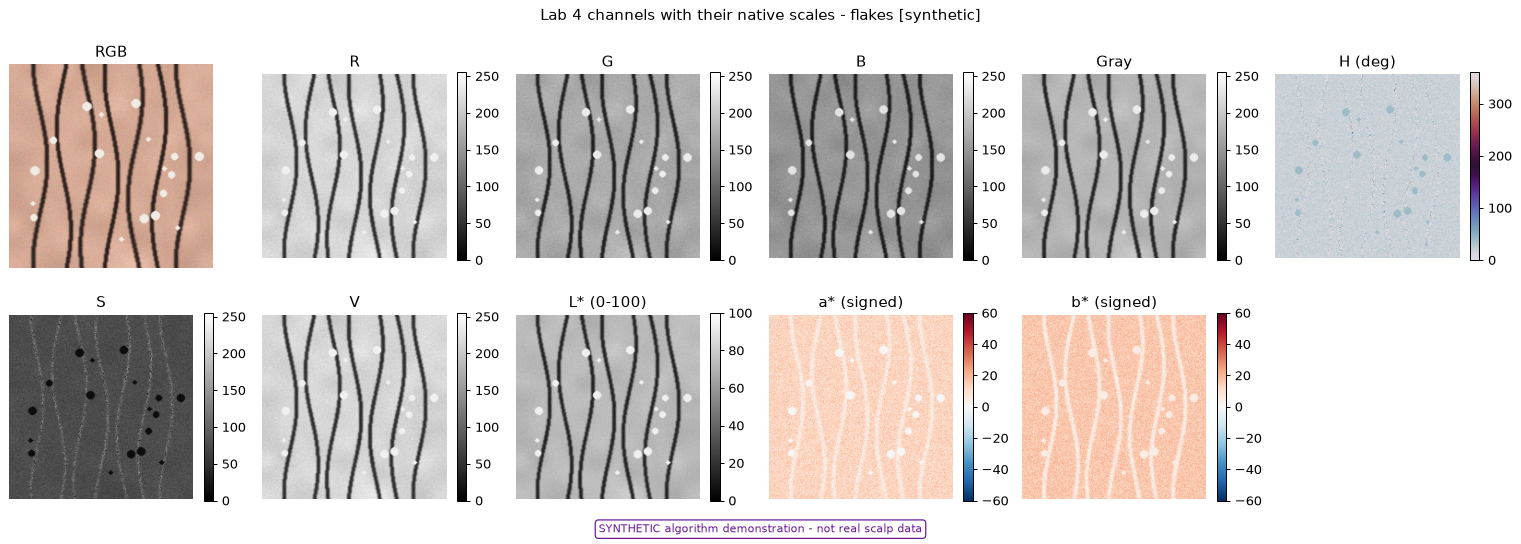

In [10]:
for rgb, name, prov in INPUTS + [(SYN["flakes"]["rgb"], "flakes", "synthetic")]:
    ch = pp.channel_stack(rgb)
    fig, axes = plt.subplots(2, 6, figsize=(17, 6))
    axes = axes.ravel()
    axes[0].imshow(rgb); axes[0].set_title("RGB"); axes[0].axis("off")
    scales = {"R": (0, 255), "G": (0, 255), "B": (0, 255), "Gray": (0, 255), "H (deg)": (0, 360), "S": (0, 255),
              "V": (0, 255), "L* (0-100)": (0, 100), "a* (signed)": (-60, 60), "b* (signed)": (-60, 60)}
    for ax, (k, v) in zip(axes[1:], ch.items()):
        cmap = "twilight" if k.startswith("H") else ("RdBu_r" if "signed" in k else "gray")
        im = ax.imshow(v, cmap=cmap, vmin=scales[k][0], vmax=scales[k][1]); ax.set_title(k); ax.axis("off")
        plt.colorbar(im, ax=ax, fraction=0.046)
    axes[-1].axis("off")
    fig.suptitle(f"Lab 4 channels with their native scales - {name} [{prov}]")
    plt.tight_layout(); save_fig(fig, f"color_channels_{name}", prov); plt.show()

## 4. Patch statistics: hair vs scalp candidates
On the synthetic image the true hair mask is known. On real images, patches come from the *candidate* hair mask
(notebook 02 method) and its complement — they are candidates, not annotated regions.

In [11]:
stats_rows = []
sources = INPUTS + [(SYN["flakes"]["rgb"], "flakes", "synthetic")]
for rgb, name, prov in sources:
    if prov == "synthetic":
        hair = (SYN["flakes"]["hair_truth"] if name == "flakes" else SYN["clean"]["hair_truth"]).astype(bool)
        region_src = "known synthetic truth"
    else:
        hair = hair_candidate_mask(pp.to_gray(rgb), cfg)[1]
        region_src = "threshold candidate"
    scalp = ~cv2.dilate(hair.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
    for k, v in pp.channel_stack(rgb).items():
        for region, m in (("hair", hair), ("scalp", scalp)):
            stats_rows.append({"image": name, "provenance": prov, "region": region, "region_source": region_src,
                               "channel": k, **pp.patch_statistics(v, m)})
patch_stats = pd.DataFrame(stats_rows)
out_csv = project_path(cfg, "results", "01_filters_color", "patch_statistics.csv", create=True)
patch_stats.to_csv(out_csv, index=False); print("saved", rel(out_csv))
patch_stats.pivot_table(index=["image", "channel"], columns="region", values="mean").round(1).head(24)

saved outputs/results/01_filters_color/patch_statistics.csv


region               hair  scalp
image   channel                 
closeup B            45.5  149.7
        G            51.8  169.8
        Gray         56.3  180.6
        H (deg)      60.3   18.8
        L* (0-100)   23.1   72.9
        R            69.3  213.7
        S            90.5   76.3
        V            69.3  213.7
        a* (signed)   6.8   13.2
        b* (signed)   7.0   16.4
flakes  B            47.8  151.3
        G            54.2  171.1
        Gray         58.6  181.8
        H (deg)      59.7   19.1
        L* (0-100)   24.0   73.3
        R            71.5  214.3
        S            89.4   75.0
        V            71.5  214.3
        a* (signed)   6.7   12.9
        b* (signed)   7.0   16.2

saved outputs/figures/01_filters_color/synthetic/SYNTHETIC_region_histograms.png


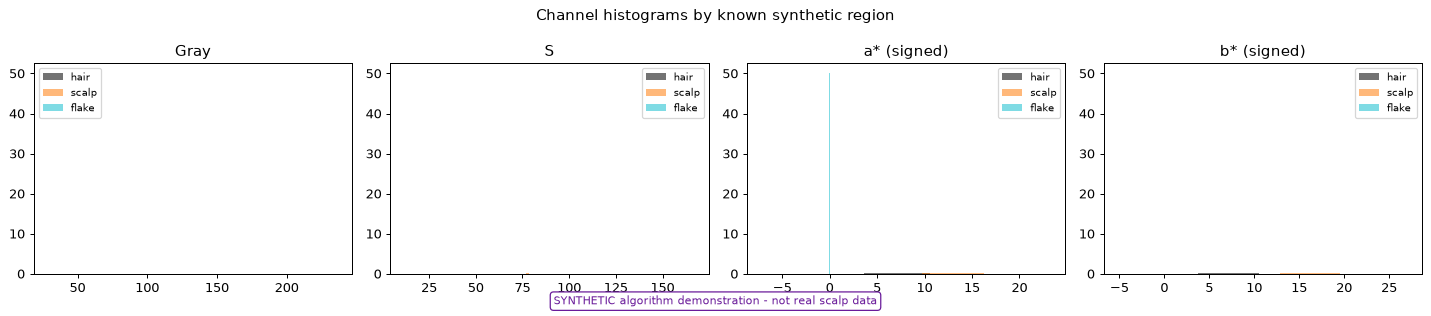

In [12]:
rgb = SYN["flakes"]["rgb"]; hair = SYN["flakes"]["hair_truth"]; flakes = SYN["flakes"]["flake_truth"]
scalp = ~(hair | flakes)
ch = pp.channel_stack(rgb)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, k in zip(axes, ["Gray", "S", "a* (signed)", "b* (signed)"]):
    for region, m, col in (("hair", hair, "k"), ("scalp", scalp, "tab:orange"), ("flake", flakes, "tab:cyan")):
        ax.hist(ch[k][m].ravel(), bins=50, alpha=.55, density=True, label=region, color=col)
    ax.set_title(k); ax.legend(fontsize=8)
fig.suptitle("Channel histograms by known synthetic region")
plt.tight_layout(); save_fig(fig, "region_histograms", "synthetic"); plt.show()

### 4.1 A bright patch is not proof of flakes
Compare a synthetic glare highlight with synthetic flakes in HSV. The flake rule used in notebook 02 accepts
bright pixels with saturation ≤ `flake_max_saturation`.

In [13]:
g = SYN["glare"]["rgb"]; f = SYN["flakes"]["rgb"]
gh, fh = pp.to_hsv(g), pp.to_hsv(f)
gl = (gh[..., 2] > 225); fl = SYN["flakes"]["flake_truth"]
smax = cfg["segmentation"]["flake_max_saturation"]
glare_tab = pd.DataFrame({"region": ["glare highlight", "true flakes"],
                          "V mean": [gh[..., 2][gl].mean(), fh[..., 2][fl].mean()],
                          "S mean": [gh[..., 1][gl].mean(), fh[..., 1][fl].mean()],
                          f"fraction with S <= {smax}": [(gh[..., 1][gl] <= smax).mean(), (fh[..., 1][fl] <= smax).mean()]})
glare_tab.round(2)

,region,V mean,S mean,fraction with S <= 70
0,glare highlight,229.2,60.22,0.4
1,true flakes,240.0,13.00,1.0


Both regions are bright. The glare highlight keeps more of the skin's saturation than the white flakes, yet a
substantial fraction of it (table) still satisfies the saturation limit — so a colour rule alone cannot separate them, and
notebook 02 shows the resulting false flake candidates.

## 5. Limitations
* PSNR/MSE are computed only against the synthetic clean image; real images have no clean reference.
* Filter rankings depend on the noise model and the scale of the structures (shaft width in pixels).
* Colour statistics are descriptors: a red pixel is not proof of inflammation, a bright patch is not proof of oil
  or flakes, and camera white balance differs across public images.
* Hue is circular and unstable at low saturation; the feature extractor therefore uses a saturation-weighted
  circular mean.

## 6. Conclusion
Mean and Gaussian smoothing trade noise for detail; Laplacian sharpening restores apparent detail but amplifies
noise and shifts boundaries. LAB/HSV channels expose colour cues for features and candidate masks, provided the
OpenCV 8-bit encodings are converted before interpretation. All functions live in `scalptrack.preprocessing`.

**References:** OpenCV image filtering and colour-conversion documentation (spec Section 24.2, refs 1–2).